In [1]:

from google.colab import files
uploaded = files.upload()


Saving devara.jpg to devara.jpg


In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt


In [3]:

filename = list(uploaded.keys())[0]
image = cv2.imread(filename)
print("Image uploaded successfully:", filename)


Image uploaded successfully: devara.jpg


In [4]:

height, width = image.shape[:2]
print("Width:", width)
print("Height:", height)


Width: 736
Height: 1634


In [6]:

source_points = np.float32([
    [50, 50],
        [width - 50, 50],
            [50, height - 50],
                [width - 50, height - 50]
                ])

destination_points = np.float32([
                    [0, 0],
                        [width, 0],
                            [100, height],
                                [width - 100, height]
                                ])


In [10]:

matrix = cv2.getPerspectiveTransform(
    source_points,
        destination_points
        )

print("Perspective Matrix:")
print(matrix)


Perspective Matrix:
[[ 1.17148041e+00  9.06153967e-02 -6.31047903e+01]
 [ 2.07155317e-17  1.48065558e+00 -7.40327791e+01]
 [ 2.05645811e-19  2.46237491e-04  1.00000000e+00]]


In [11]:

perspective_image = cv2.warpPerspective(
  image,
        matrix,
            (width, height)
            )


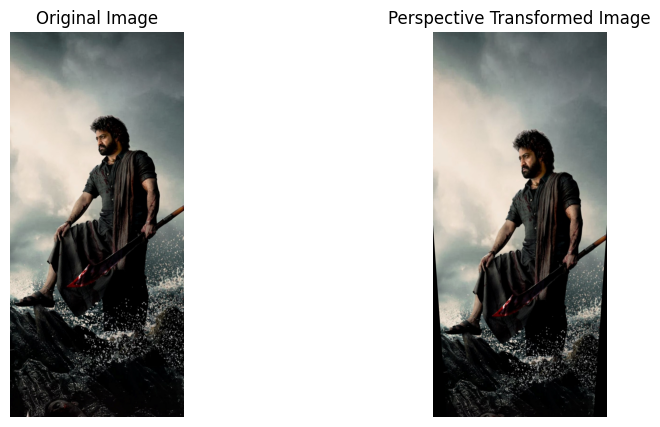

In [12]:

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(perspective_image, cv2.COLOR_BGR2RGB))
plt.title("Perspective Transformed Image")
plt.axis("off")

plt.show()
